# Valoración de opciones con simulación Monte Carlo

<div class="aperture-pasos">

## Monte Carlo aplicado a opciones

1. **Generar normales Z**<br>
2. **Simular el precio final**<br>
3. **Calcular el pago**<br>
4. **Promediar los pagos**<br>
5. **Descontar a hoy**<br>
6. **Estimar precio y error**<br>
</div>

### Datos: opción call europea sobre Amazon (AMZN)

Se valora una opción call europea sobre una acción de Amazon con vencimiento en 6 meses y strike igual al múltiplo de 5 más cercano al precio actual (*at-the-money*). La volatilidad se estima con los últimos 5 años de precios de cierre ajustados y la tasa libre de riesgo es la de la letra del Tesoro a 13 semanas (`^IRX`), ambas descargadas de Yahoo Finance con `yfinance`.

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
from scipy import stats

# Parámetros del análisis
TICKER = "AMZN"
INICIO, FIN = "2021-11-01", "2026-11-01"  # 5 años para estimar la volatilidad
T = 0.5  # años al vencimiento
N_SIM = 100_000
SEMILLA = 42

precios = yf.download(TICKER, start=INICIO, end=FIN, auto_adjust=True, progress=False)["Close"][TICKER].dropna()
rendimientos = np.log(precios).diff().dropna()

S0 = precios.iloc[-1]  # precio actual
K = round(S0 / 5) * 5  # strike: múltiplo de 5 más cercano (at-the-money)
sigma = rendimientos.std() * np.sqrt(252)  # volatilidad anual

# Tasa libre de riesgo: letra del Tesoro a 13 semanas, convertida a tasa continua
irx = yf.download("^IRX", start=INICIO, end=FIN, auto_adjust=True, progress=False)["Close"]["^IRX"].dropna()
r = np.log(1 + irx.iloc[-1] / 100)

print(f"Datos de {precios.index[0]:%Y-%m-%d} a {precios.index[-1]:%Y-%m-%d} ({len(precios)} días)")
pd.Series(
    {
        "precio actual S0 (USD)": f"{S0:,.2f}",
        "strike K (USD)": f"{K:,.0f}",
        "volatilidad anual σ": f"{sigma:.2%}",
        "tasa libre de riesgo r": f"{r:.2%}",
        "vencimiento T (años)": f"{T}",
        "escenarios N": f"{N_SIM:,}",
    },
    name="valor",
).to_frame()

Datos de 2021-11-01 a 2026-10-30 (1255 días)


,valor
precio actual S0 (USD),240.35
strike K (USD),240
volatilidad anual σ,36.52%
tasa libre de riesgo r,3.90%
vencimiento T (años),0.5
escenarios N,"100,000"


In [2]:
# Gráficas con la estética de la charla: el código está en graficas.py
import graficas

graficas.aplicar_estilo()

> **Qué se hizo.** Se definieron los parámetros de la opción a partir de datos de mercado.
>
> **Cómo.** `yf.download` trae 5 años de precios de AMZN; la volatilidad anual es la desviación de los rendimientos logarítmicos diarios por √252. La tasa libre de riesgo es la de `^IRX` (letra del Tesoro a 13 semanas), convertida a tasa continua con `log(1 + tasa)`. El strike es el múltiplo de 5 más cercano al precio actual.
>
> **Resultado.** S0 = USD 240.35, K = USD 240, σ = 36.52% anual, r = 3.90% anual y T = 0.5 años.

## Generar normales Z

Números aleatorios con distribución N(0, 1).

In [3]:
rng = np.random.default_rng(SEMILLA)
Z = rng.standard_normal(N_SIM)

# Prueba de Kolmogorov-Smirnov contra la normal estándar
ks = stats.kstest(Z, "norm")
pd.DataFrame(
    {
        "simulado": [Z.mean(), Z.std(), stats.skew(Z), stats.kurtosis(Z), ks.pvalue],
        "teórico": [0, 1, 0, 0, None],
    },
    index=["media", "desv. estándar", "asimetría", "curtosis (exceso)", "p-valor KS"],
).round(4)

,simulado,teórico
media,-0.0042,0.0
desv. estándar,1.0037,1.0
asimetría,0.0068,0.0
curtosis (exceso),0.0228,0.0
p-valor KS,0.0477,NaN


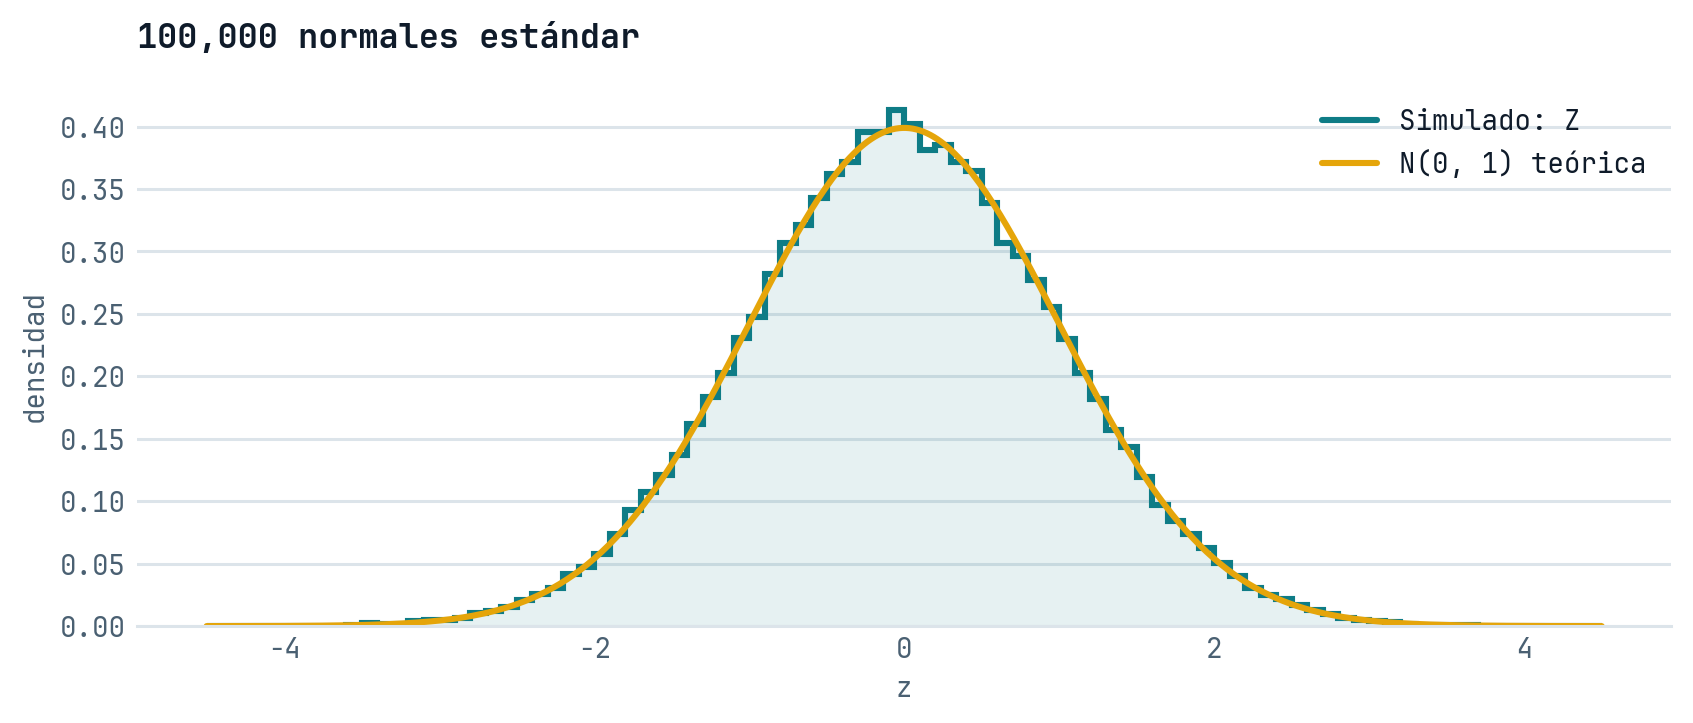

In [4]:
graficas.normales(Z, "Simulado: Z", f"{N_SIM:,} normales estándar", "op_01_normales")

> **Qué se hizo.** Se generaron 100,000 números aleatorios con distribución normal estándar, uno por escenario.
>
> **Cómo.** `np.random.default_rng(42).standard_normal` con semilla fija para que el resultado sea reproducible. Se compararon los momentos con los teóricos y se aplicó la prueba de Kolmogorov-Smirnov (`stats.kstest`).
>
> **Resultado.** Media −0.004, desviación 1.004, asimetría y curtosis prácticamente 0; el histograma sigue la campana teórica. El p-valor KS de 0.048 queda justo en el límite del 5%: con muestras realmente normales, 1 de cada 20 semillas da un p-valor así de bajo por azar.

## Simular el precio final

`S_T = S0 · exp((r − σ²/2)·T + σ·√T · Z)`

In [5]:
# Movimiento browniano geométrico bajo la medida neutral al riesgo
S_T = S0 * np.exp((r - sigma**2 / 2) * T + sigma * np.sqrt(T) * Z)

# Chequeo: bajo neutralidad al riesgo, E[S_T] = S0·e^(rT)
media_teorica = S0 * np.exp(r * T)
pd.DataFrame(
    {
        "simulado": [S_T.mean(), S_T.std()],
        "teórico": [media_teorica, media_teorica * np.sqrt(np.exp(sigma**2 * T) - 1)],
    },
    index=["media (USD)", "desv. estándar (USD)"],
).round(2)

,simulado,teórico
media (USD),244.88,245.08
desv. estándar (USD),64.64,64.36


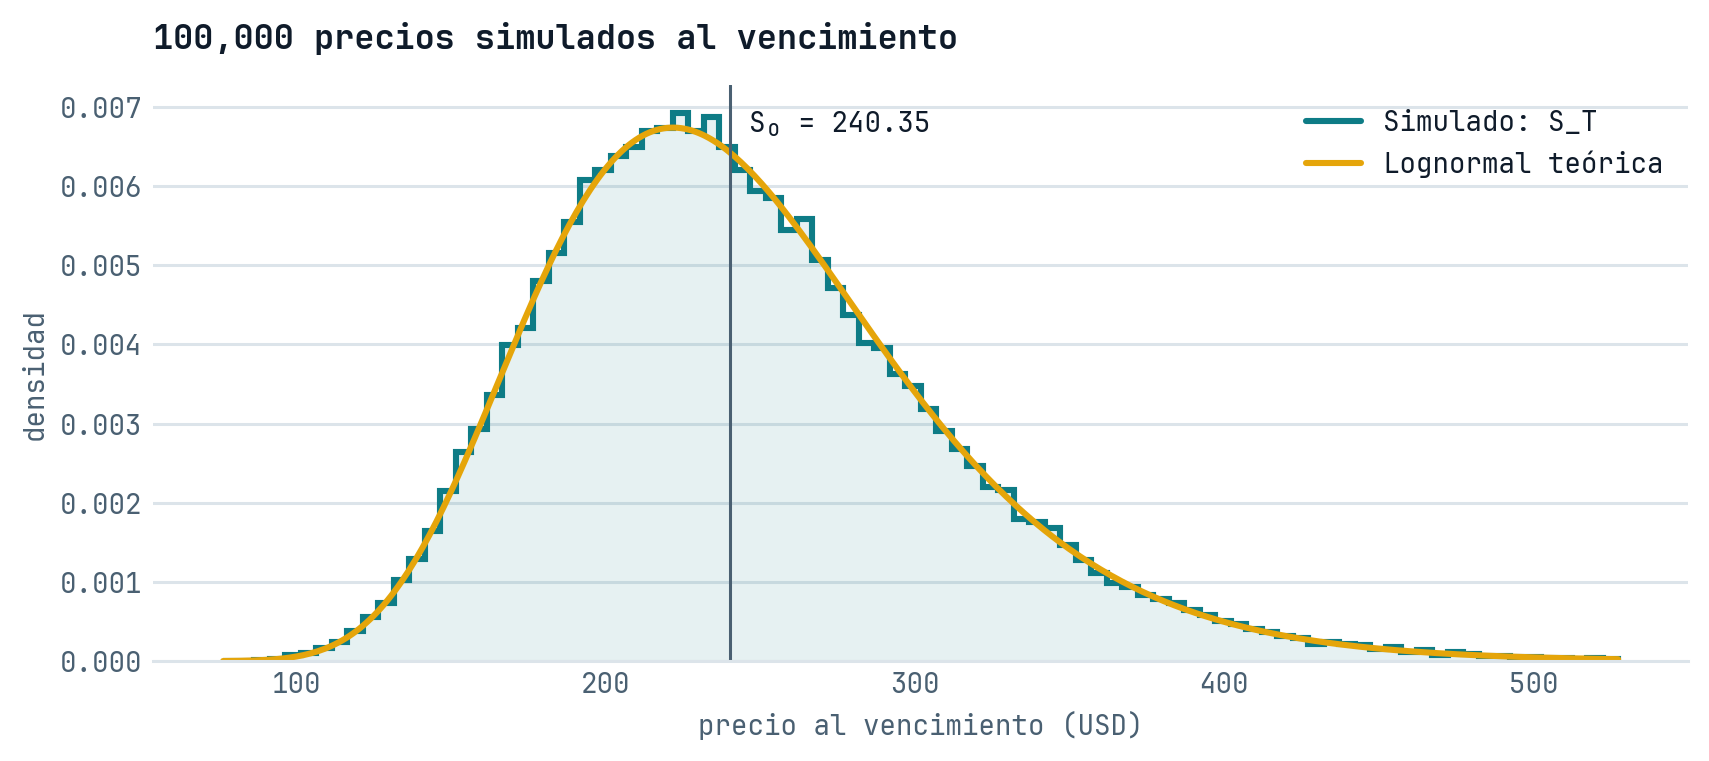

In [6]:
graficas.precio_final(S_T, S0, r, sigma, T)

> **Qué se hizo.** Se simuló el precio de AMZN al vencimiento en cada escenario.
>
> **Cómo.** Movimiento browniano geométrico bajo la medida neutral al riesgo: `S_T = S0 · exp((r − σ²/2)·T + σ·√T · Z)`. El término −σ²/2 corrige la media para que el precio esperado crezca exactamente a la tasa libre de riesgo.
>
> **Resultado.** La media simulada es USD 244.88 frente a S0·e^(rT) = USD 245.08 teórico. La distribución es lognormal: asimétrica a la derecha, porque el precio no puede ser negativo pero sí puede subir mucho.

## Calcular el pago

`max(S_T − K, 0)` en cada escenario.

In [7]:
pagos = np.maximum(S_T - K, 0)

print(f"Escenarios que pagan: {(pagos > 0).mean():.1%} de {N_SIM:,}")
pd.Series(pagos, name="pago (USD)").describe(percentiles=[0.25, 0.5, 0.75, 0.95]).round(2).to_frame()

Escenarios que pagan: 47.7% de 100,000


,pago (USD)
count,100000.00
mean,27.49
std,45.03
min,0.00
25%,0.00
50%,0.00
75%,41.79
95%,122.65
max,623.79


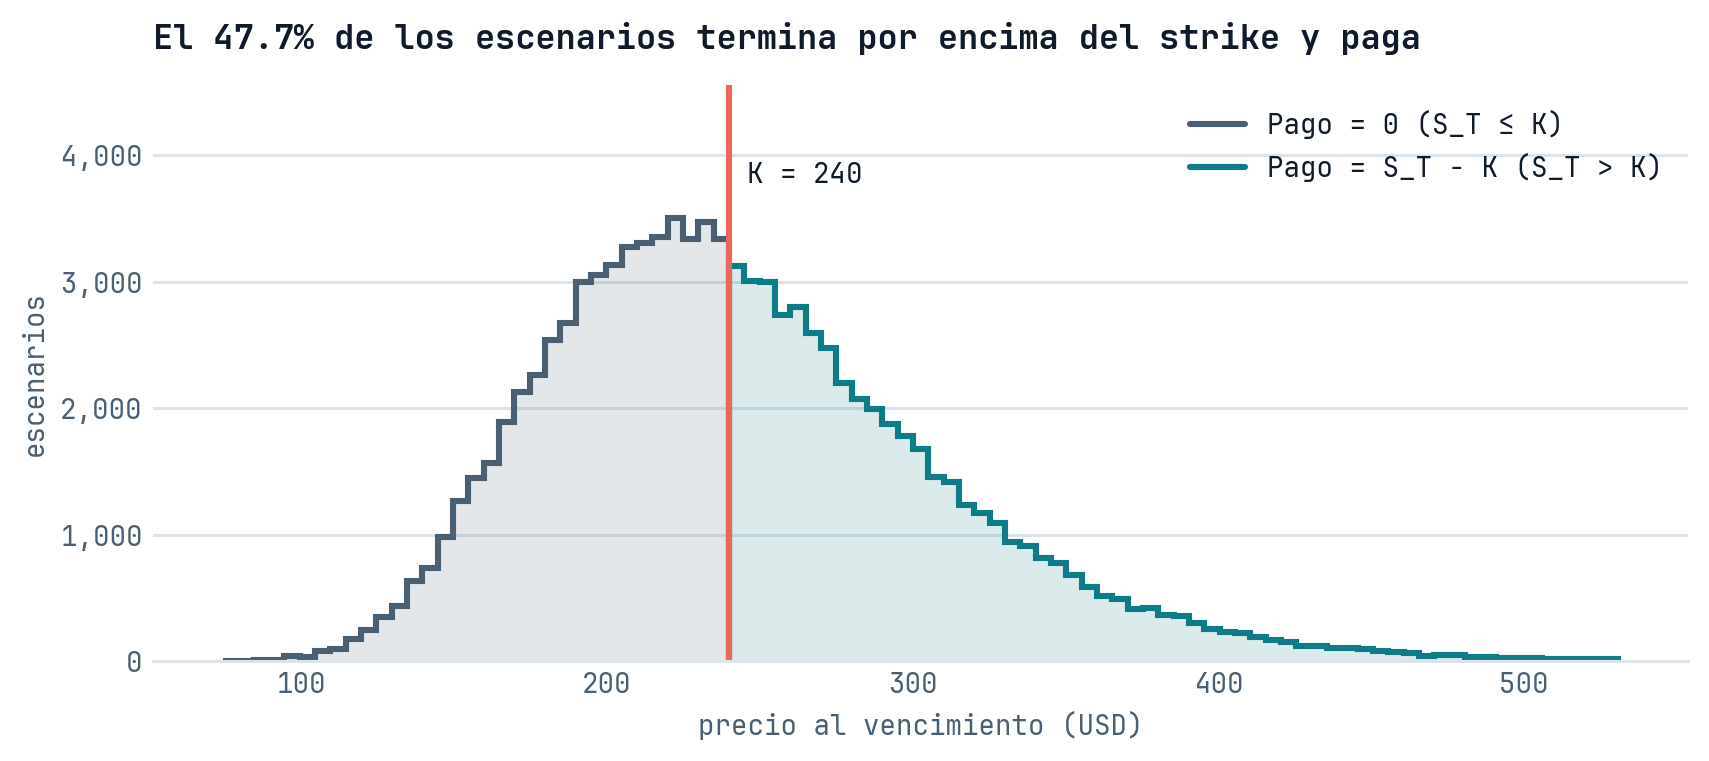

In [8]:
graficas.pagos(S_T, K)

> **Qué se hizo.** Se calculó el pago de la opción call en cada escenario.
>
> **Cómo.** `np.maximum(S_T − K, 0)`: si el precio final supera el strike, el dueño ejerce y gana la diferencia; si no, la opción vence sin valor.
>
> **Resultado.** El 47.7% de los escenarios paga algo; en el resto el pago es 0, por eso la mediana es 0. El pago máximo simulado es USD 623.79 y el 5% de los escenarios paga más de USD 122.65.

## Promediar los pagos

Media de los N escenarios simulados.

In [9]:
pago_esperado = pagos.mean()

print(f"Pago esperado al vencimiento: USD {pago_esperado:,.4f}")

Pago esperado al vencimiento: USD 27.4862


> **Qué se hizo.** Se estimó el pago esperado de la opción al vencimiento.
>
> **Cómo.** Promedio simple de los 100,000 pagos con `pagos.mean()`: por la ley de los grandes números, la media muestral converge al valor esperado.
>
> **Resultado.** El pago esperado al vencimiento es USD 27.49.

## Descontar a hoy

Multiplicar el promedio por `e^(−rT)`.

In [10]:
factor = np.exp(-r * T)
precio_mc = factor * pago_esperado

print(f"Factor de descuento e^(-rT): {factor:.6f}")
print(f"Precio Monte Carlo del call: USD {precio_mc:,.4f}")

Factor de descuento e^(-rT): 0.980708
Precio Monte Carlo del call: USD 26.9559


> **Qué se hizo.** Se trajo el pago esperado a valor presente.
>
> **Cómo.** Se multiplicó por el factor de descuento continuo `e^(−rT)`, porque el pago ocurre dentro de 6 meses y un dólar futuro vale menos que uno de hoy.
>
> **Resultado.** Con un factor de 0.9807, el precio Monte Carlo del call es **USD 26.96**.

## Estimar precio y error

Intervalo del 95% con `± 1.96 · s/√N`.

In [11]:
descontados = factor * pagos  # pago descontado de cada escenario
s = descontados.std(ddof=1)
error_estandar = s / np.sqrt(N_SIM)
margen = 1.96 * error_estandar

print(f"Precio: USD {precio_mc:,.4f} ± {margen:,.4f}")
print(f"Intervalo del 95%: USD {precio_mc - margen:,.4f} a USD {precio_mc + margen:,.4f}")

# El error se reduce como 1/√N: usar los primeros N escenarios
n = [1_000, 10_000, 100_000]
pd.DataFrame(
    {
        "precio (USD)": [descontados[:m].mean() for m in n],
        "error estándar": [descontados[:m].std(ddof=1) / np.sqrt(m) for m in n],
    },
    index=pd.Index([f"{m:,}" for m in n], name="N"),
).assign(**{"± 95%": lambda d: 1.96 * d["error estándar"]}).round(4)

Precio: USD 26.9559 ± 0.2737
Intervalo del 95%: USD 26.6822 a USD 27.2296


,precio (USD),error estándar,± 95%
N,,,
"1,000",25.2816,1.3323,2.6113
"10,000",26.7351,0.4410,0.8643
"100,000",26.9559,0.1396,0.2737


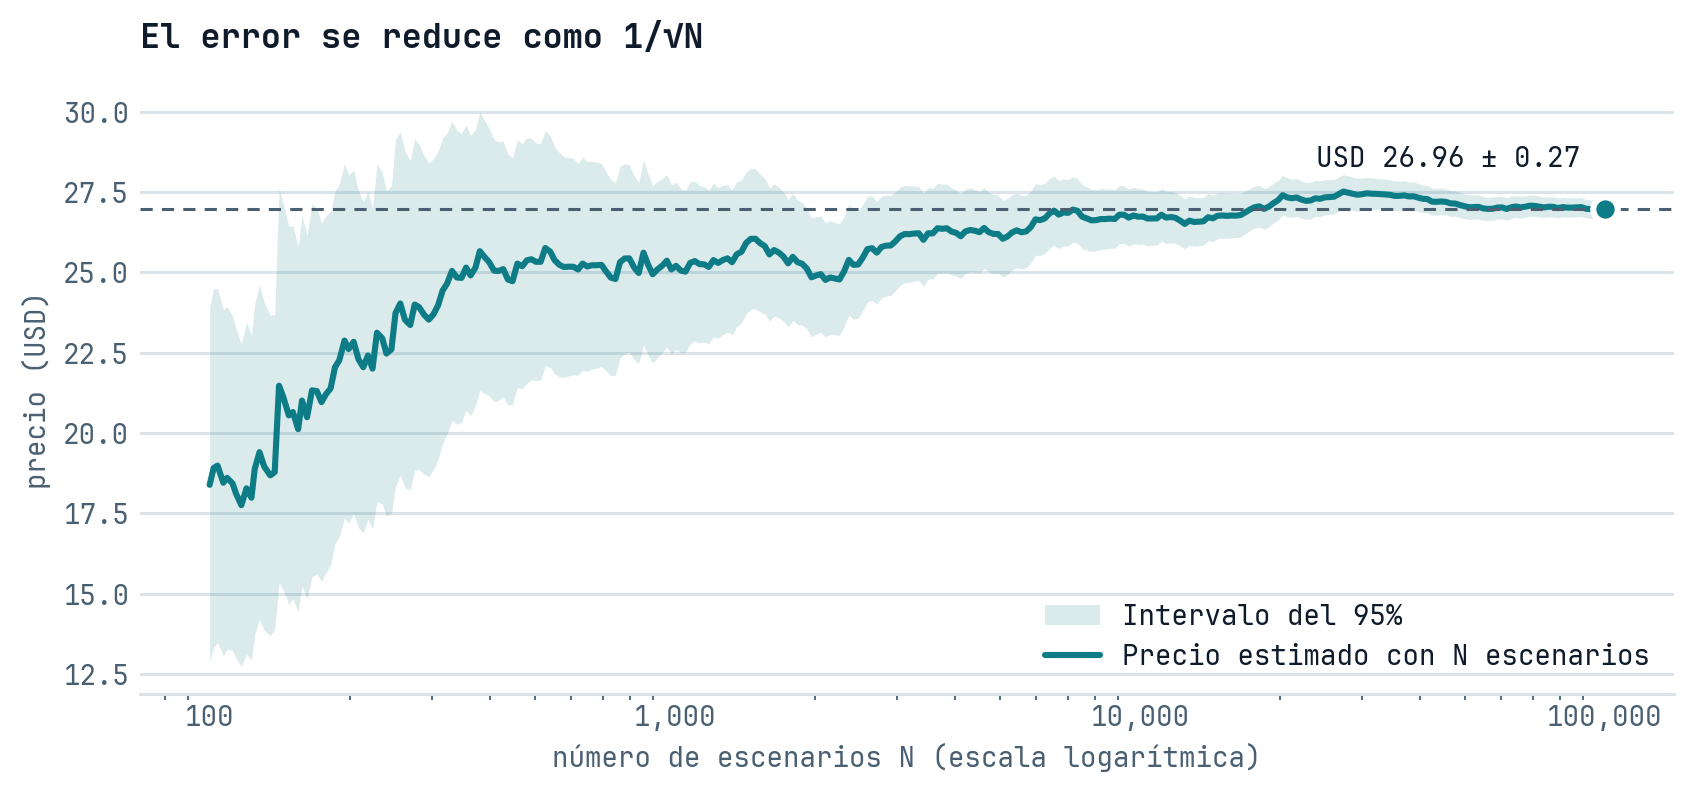

In [12]:
graficas.convergencia(descontados)

> **Qué se hizo.** Se midió la precisión del precio con un intervalo de confianza del 95%.
>
> **Cómo.** El error estándar es `s/√N`, donde s es la desviación de los pagos descontados; el intervalo es el precio ± 1.96 errores estándar. Se repitió con los primeros 1,000 y 10,000 escenarios para ver cómo cambia.
>
> **Resultado.** Precio de USD 26.96 ± 0.27, con intervalo de USD 26.68 a USD 27.23. El margen pasa de ± 2.61 con 1,000 escenarios a ± 0.86 con 10,000 y ± 0.27 con 100,000: cada vez que N se multiplica por 10, el error se divide por cerca de √10 ≈ 3.2.

<div class="aperture-cierre">

## Conclusiones

</div>

1. **El precio Monte Carlo de un call europeo *at-the-money* sobre AMZN a 6 meses es USD 26.96 ± 0.27** (intervalo del 95%: USD 26.68 a USD 27.23), alrededor del 11% del precio de la acción.
2. **Cada paso se puede verificar.** Las normales simuladas siguen la campana teórica y el precio final simulado tiene la media que exige la neutralidad al riesgo (USD 244.88 frente a USD 245.08).
3. **El precio es un valor esperado descontado.** En más de la mitad de los escenarios la opción no paga nada; su valor viene de los escenarios en los que AMZN sube por encima del strike.
4. **La precisión cuesta escenarios.** El error se reduce como 1/√N: para dividirlo entre 10 hay que simular 100 veces más escenarios.
5. **El resultado depende de los supuestos.** Se asumió volatilidad constante, estimada con 5 años de historia, y precios lognormales; otra ventana de datos o colas más pesadas darían otro precio.
6. **El método se generaliza.** Para valorar opciones sin fórmula cerrada, como asiáticas o con barrera, basta con cambiar cómo se simula la trayectoria y cómo se calcula el pago (pasos 02 y 03); el promedio, el descuento y el intervalo de confianza no cambian.